# Day 11 — Spatial Autocorrelation and Blocked Validation

Day 6 established the three-way split: train to learn, validation to choose, test used
once. That discipline rests on an assumption that was never stated — **the samples in
the three sets are independent.**

For CIFAR-10 it holds: every image was photographed separately.

**For satellite imagery it does not.** Two neighbouring patches cut from the same scene
sample ground a few tens of metres apart. They share land cover, illumination,
atmospheric state and sensor state. With overlapping strides they literally share
pixels.

After a random split, a validation patch can sit 64 pixels from a training patch. The
model saw that ground during training and sees it again at validation. **That is not a
generalization test; it is a memory test.**

This notebook measures how much that inflates the validation score.

## The experiment

One scene, three sets:

| set | how it is formed |
|---|---|
| **TEST** | a geographically separate region, held out from the start, never used for anything but the final number |
| **split A** | train/val assigned by shuffling tiles — the common, wrong approach |
| **split B** | train/val assigned by spatial block, with a buffer wider than the autocorrelation range |

Both splits train the same architecture on the same number of tiles. Then:

**optimism = validation score − test score.**

Whichever split has the smaller optimism is the honest one. The held-out region is what
makes this checkable — without an independent judge, two different numbers are just two
different numbers.

## Why this is worth a whole notebook

Random splitting of image patches is probably the single most common methodological
error in published remote-sensing deep learning. It produces validation scores that look
excellent and models that fail on the next region, and the failure is invisible until
deployment.

## 0. Setup

Runs locally on Apple Silicon (MPS). Requires `rasterio` and `scipy`, both already
installed from Day 10.

In [3]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"     # must precede `import torch`

import time, copy
import numpy as np
import rasterio
from rasterio.transform import from_origin
from rasterio.windows import Window
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print("device:", device)

WORK = os.path.expanduser("~/dl-local/geo")
os.makedirs(WORK, exist_ok=True)

IGNORE = 255
N_CLS = 3
CLS_NAMES = ["low", "mid", "high"]
TILE = 128

def seed_all(s=42):
    torch.manual_seed(s)
    if device == "mps":
        torch.mps.manual_seed(s)
    elif device == "cuda":
        torch.cuda.manual_seed_all(s)

device: mps


## 1. A scene with the two properties that matter

Day 10's synthetic scene used a periodic sine pattern. That is useless here: with a
repeating pattern, a distant region looks exactly like a nearby one, so a blocked split
would show no effect at all.

Real imagery has two properties this experiment depends on:

**Spatial autocorrelation** — neighbouring pixels are similar. Generated by smoothing
white noise, which gives a controllable correlation length.

**Spatial non-stationarity** — the class mix differs systematically between regions.
Generated by adding a large-scale trend. This is what makes a model that validates well
locally still fail on a new area, and it is the realistic part: land cover, ice type and
sea state all vary regionally.

In [4]:
def make_spatial_scene(path, lbl_path, H=2048, W=2048, corr_px=40,
                       hidden_w=0.9, hidden_sigma=70, seed=0):
    """Scene with autocorrelation, a regional trend, and a hidden label component.

    Three ingredients, each load-bearing:

    1. `local` + `broad` -- smoothed Gaussian noise at two scales. This is the
       spatial autocorrelation, and it is what the bands encode.
    2. `trend` -- a north-south plus east-west gradient, making the class mix
       regionally non-stationary.
    3. `hidden` -- an autocorrelated field that affects the LABELS but is NOT
       encoded in the bands. See section 1b: without it the task is pointwise
       invertible and leakage has nothing to exploit.
    """
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:H, 0:W]

    def field(sigma, off):
        r = np.random.default_rng(seed + off).normal(0, 1, (H, W))
        f = gaussian_filter(r, sigma=sigma)
        return (f - f.mean()) / (f.std() + 1e-9)

    local = field(corr_px, 1)              # fine structure
    broad = field(corr_px * 6, 2)          # regional structure
    trend = (yy / H - 0.5) * 2.0 + (xx / W - 0.5) * 0.8

    signal = 0.55 * local + 0.85 * broad + 1.0 * trend   # what the BANDS encode
    hidden = field(hidden_sigma, 5)                       # NOT in the bands
    label_signal = signal + hidden_w * hidden             # what the LABELS follow

    bands = np.stack([
        signal * 1100 + 3000 + rng.normal(0, 90,  (H, W)),
        signal *  850 + 2200 + rng.normal(0, 75,  (H, W)),
        signal *  550 + 1500 + rng.normal(0, 60,  (H, W)),
        signal * 2300 + 8000 + rng.normal(0, 220, (H, W)),
    ]).astype(np.int16)

    nod = (yy + xx) < 400
    bands[:, nod] = -9999

    valid = ~nod
    q = np.quantile(label_signal[valid], [0.33, 0.70])
    lab = np.full((H, W), IGNORE, dtype=np.uint8)
    lab[valid & (label_signal <  q[0])] = 0
    lab[valid & (label_signal >= q[0]) & (label_signal < q[1])] = 1
    lab[valid & (label_signal >= q[1])] = 2

    transform = from_origin(499980.0, 5600040.0, 10.0, 10.0)
    prof = dict(driver="GTiff", height=H, width=W, crs="EPSG:32633",
                transform=transform, tiled=True, blockxsize=256, blockysize=256,
                compress="deflate")
    with rasterio.open(path, "w", count=4, dtype="int16", nodata=-9999, **prof) as d:
        d.write(bands)
    with rasterio.open(lbl_path, "w", count=1, dtype="uint8", nodata=IGNORE, **prof) as d:
        d.write(lab, 1)

    # How much of the label is explainable from what the bands carry?
    r2 = np.corrcoef(signal[valid].ravel(), label_signal[valid].ravel())[0, 1] ** 2
    return path, lbl_path, signal, lab, r2


scene, labels, signal, lab, R2 = make_spatial_scene(
    f"{WORK}/spatial.tif", f"{WORK}/spatial_labels.tif")
print("wrote", scene)
print(f"\nlabel variance explainable from the bands: R^2 = {R2:.3f}")
print(f"the remaining {100*(1-R2):.0f}% is obtainable only by memorising locations")

print("\nclass share by region (non-stationarity check):")
print("  region      low     mid    high")
for name, sl in [("north ", slice(0, 512)), ("mid-n ", slice(512, 1024)),
                 ("mid-s ", slice(1024, 1536)), ("south ", slice(1536, 2048))]:
    seg = lab[sl]; seg = seg[seg != IGNORE]
    print(f"  {name} " + "  ".join(f"{(seg == k).mean()*100:5.1f}%" for k in range(3)))

wrote /Users/ttian/dl-local/geo/spatial.tif

label variance explainable from the bands: R^2 = 0.546
the remaining 45% is obtainable only by memorising locations

class share by region (non-stationarity check):
  region      low     mid    high
  north   37.7%   36.1%   26.2%
  mid-n   41.8%   37.0%   21.2%
  mid-s   35.1%   31.3%   33.6%
  south   17.8%   43.5%   38.7%


If the class shares differ substantially between north and south, the non-stationarity
is there. **That difference is the reason a locally validated model can still fail on a
new region** — and the reason the held-out test region below is a meaningful judge.

## 1b. Why the labels need a component the bands do not carry

The `hidden` term above is not decoration. The first version of this notebook left it
out: labels were quantiles of the same `signal` the bands encode. The experiment ran
cleanly and showed **nothing** —

```
random   val 0.9494 -> TEST 0.9476   optimism +0.0018
blocked  val 0.9688 -> TEST 0.9612   optimism +0.0076
```

Both models scored ~0.95 on held-out ground and neither validation score was optimistic.

The reason is worth more than the fix. With labels a deterministic pointwise function of
the band values, the task is **pointwise invertible**: learn one lookup from four numbers
to a class and it transfers perfectly anywhere. There is nothing a model could gain by
memorising a location, so leakage has nothing to exploit. **The experiment could not
have produced a positive result, whatever the split.**

Leakage pays only when the task contains something the input cannot explain, so that
memorising specific ground is the only route to those labels. That is the realistic
case: ice-chart polygons carry analyst convention, land-cover labels carry local
mapping rules, and none of it is visible in the pixels.

`hidden` supplies exactly that — spatially autocorrelated, absent from the bands. The
printed R² is how much of the label a perfect pointwise model could reach; the rest is
available only by memorisation.

**And a CNN can memorise location**, even without coordinates as input: the noise
texture of each patch of ground is a unique fingerprint. "This texture → label shifted
up" is learnable, and it transfers to an adjacent tile that shares most of that texture.
That is the leakage mechanism, concretely.

> An experiment that cannot fail tells you nothing. Before running a comparison, it is
> worth asking what result would falsify the hypothesis — and whether the setup admits
> that result at all.

## 2. Semivariogram — measuring the autocorrelation range

Geostatistics has a standard tool for exactly this question, and it predates machine
learning by decades.

```
γ(h) = ½ · E[(Z(x) − Z(x+h))²]
```

Take all pairs of points separated by distance `h`, average half their squared
difference. Small `h` gives small γ (nearby points are similar). As `h` grows, γ rises
and then **flattens**. The distance at which it flattens is the **range**.

**Beyond the range, two samples are effectively independent.** That number is what
should set the block size and buffer width of a spatial split — not a guess.

Tobler's first law states the principle ("near things are more related than distant
things"); the semivariogram quantifies it.

sill  (plateau variance) : 914,639
range (95% of sill)      : 360 px = 3601 m at 10 m GSD
tile size                : 128 px
range / tile             : 2.81


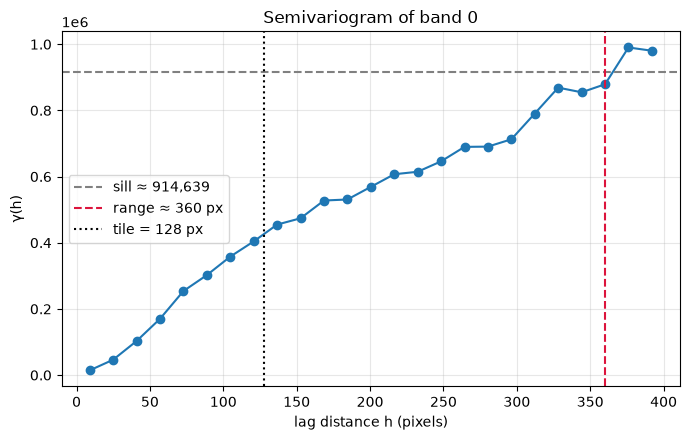

In [5]:
def semivariogram(arr, valid, max_lag=400, n_lags=25, n_pairs=60000, seed=0):
    """Empirical semivariogram from randomly sampled point pairs.

    Sampling pairs rather than enumerating all of them keeps this O(n_pairs)
    instead of O(n^2).
    """
    rng = np.random.default_rng(seed)
    H, W = arr.shape
    edges = np.linspace(1, max_lag, n_lags + 1)
    sums = np.zeros(n_lags); counts = np.zeros(n_lags)

    for _ in range(n_pairs):
        r1 = rng.integers(0, H); c1 = rng.integers(0, W)
        if not valid[r1, c1]:
            continue
        h = rng.uniform(1, max_lag); th = rng.uniform(0, 2 * np.pi)
        r2 = int(r1 + h * np.sin(th)); c2 = int(c1 + h * np.cos(th))
        if not (0 <= r2 < H and 0 <= c2 < W) or not valid[r2, c2]:
            continue
        d = np.hypot(r2 - r1, c2 - c1)
        b = np.searchsorted(edges, d) - 1
        if 0 <= b < n_lags:
            sums[b] += (float(arr[r1, c1]) - float(arr[r2, c2])) ** 2
            counts[b] += 1

    centers = 0.5 * (edges[:-1] + edges[1:])
    gamma = np.where(counts > 0, 0.5 * sums / np.maximum(counts, 1), np.nan)
    return centers, gamma, counts


with rasterio.open(scene) as src:
    b0 = src.read(1).astype(np.float32)
    nod = src.nodata
valid_mask = b0 != nod

h, g, n = semivariogram(b0, valid_mask, max_lag=400, n_lags=25)

sill = np.nanmean(g[-5:])
idx = np.where(g >= 0.95 * sill)[0]
RANGE_PX = float(h[idx[0]]) if len(idx) else float("nan")

print(f"sill  (plateau variance) : {sill:,.0f}")
print(f"range (95% of sill)      : {RANGE_PX:.0f} px = {RANGE_PX*10:.0f} m at 10 m GSD")
print(f"tile size                : {TILE} px")
print(f"range / tile             : {RANGE_PX/TILE:.2f}")

plt.figure(figsize=(7, 4.5))
plt.plot(h, g, "o-")
plt.axhline(sill, ls="--", c="gray", label=f"sill ≈ {sill:,.0f}")
plt.axvline(RANGE_PX, ls="--", c="crimson", label=f"range ≈ {RANGE_PX:.0f} px")
plt.axvline(TILE, ls=":", c="k", label=f"tile = {TILE} px")
plt.xlabel("lag distance h (pixels)"); plt.ylabel("γ(h)")
plt.legend(); plt.grid(alpha=.3); plt.title("Semivariogram of band 0")
plt.tight_layout(); plt.show()

**The relative position of the red line (range) and the black line (tile size) is the
whole argument.** If the range exceeds the tile size, tiles that are immediate
neighbours are statistically dependent, and a random split over tiles necessarily leaks.

The buffer width below is derived from this measured range rather than picked by hand.

## 3. Three sets

**TEST is carved off first and geographically**: the southern quarter of the scene. It
is never used for training or selection. Both split strategies are judged against it.

The remaining northern three-quarters is the pool that gets split two ways:

- **A — random**: shuffle all pool tiles, 80/20.
- **B — blocked**: partition the pool into square blocks of tiles, assign whole blocks
  to train or val, then **delete any training tile within `buffer` pixels of a
  validation tile**. The buffer is set from the measured range.

The buffer is rounded up from the measured range to a whole number of tiles, so it is
typically two or three tiles wide. That removes a substantial fraction of the training
pool — which is the real cost of doing this correctly, and worth seeing.

A control that matters: **both strategies must train on the same number of tiles.** The
buffer removes tiles from B, so A is subsampled to match. Without this, any difference
could be explained by training-set size instead of by leakage.

In [6]:
def enumerate_tiles(scene_path, size=TILE, stride=TILE, min_valid=0.6):
    """All (col, row) tile origins with enough valid data."""
    with rasterio.open(scene_path) as src:
        H, W, nodv = src.height, src.width, src.nodata
        out = []
        for r in range(0, H - size + 1, stride):
            for c in range(0, W - size + 1, stride):
                a = src.read(1, window=Window(c, r, size, size))
                if (a != nodv).mean() >= min_valid:
                    out.append((c, r))
    return out, H, W


all_tiles, H, W = enumerate_tiles(scene)
TEST_ROW0 = 1536                                    # southern quarter -> TEST

pool_tiles = [(c, r) for c, r in all_tiles if r + TILE <= TEST_ROW0]
test_tiles = [(c, r) for c, r in all_tiles if r >= TEST_ROW0]
print(f"all {len(all_tiles)} | pool {len(pool_tiles)} | test {len(test_tiles)}")


def split_random(tiles, val_frac=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(tiles))
    nval = int(round(val_frac * len(tiles)))
    val = [tiles[i] for i in idx[:nval]]
    tr  = [tiles[i] for i in idx[nval:]]
    return tr, val


def split_blocked(tiles, block_tiles=4, val_frac=0.2, buffer_px=0, seed=0):
    """Assign whole spatial blocks to train or val, then buffer the train side.

    buffer_px should exceed the autocorrelation range: any training tile whose
    centre is within that distance of a validation tile centre is dropped, so
    the two sets are not merely disjoint but statistically independent.
    """
    rng = np.random.default_rng(seed)
    bsz = block_tiles * TILE
    blocks = {}
    for c, r in tiles:
        blocks.setdefault((c // bsz, r // bsz), []).append((c, r))

    keys = sorted(blocks)
    k = max(1, int(round(val_frac * len(keys))))
    val_keys = set(map(tuple, np.array(keys)[rng.permutation(len(keys))[:k]].tolist()))

    val = [t for kk in val_keys for t in blocks[kk]]
    tr_all = [t for kk in keys if kk not in val_keys for t in blocks[kk]]

    if buffer_px > 0 and val:
        vc = np.array([[c + TILE / 2, r + TILE / 2] for c, r in val])
        tr = []
        for c, r in tr_all:
            d = np.hypot(vc[:, 0] - (c + TILE / 2), vc[:, 1] - (r + TILE / 2)).min()
            if d > buffer_px:
                tr.append((c, r))
    else:
        tr = tr_all
    return tr, val, len(tr_all) - len(tr)


BUFFER = float(np.ceil(RANGE_PX / TILE) * TILE)     # round the range up to whole tiles
print(f"\nbuffer = {BUFFER:.0f} px (range {RANGE_PX:.0f} px rounded up to whole tiles)")

tr_rand_full, val_rand = split_random(pool_tiles, 0.2, seed=0)
tr_blk, val_blk, dropped = split_blocked(pool_tiles, block_tiles=4, val_frac=0.2,
                                         buffer_px=BUFFER, seed=0)

# Match training-set sizes so the comparison is not confounded by data volume
n_match = min(len(tr_rand_full), len(tr_blk))
rng = np.random.default_rng(1)
tr_rand = [tr_rand_full[i] for i in rng.permutation(len(tr_rand_full))[:n_match]]
tr_blk  = [tr_blk[i]       for i in rng.permutation(len(tr_blk))[:n_match]]

print(f"\nA random  : train {len(tr_rand):3d}  val {len(val_rand):3d}")
print(f"B blocked : train {len(tr_blk):3d}  val {len(val_blk):3d}  "
      f"({dropped} train tiles dropped by the buffer)")
print(f"TEST      : {len(test_tiles)} tiles, southern quarter, untouched")

all 250 | pool 186 | test 64

buffer = 384 px (range 360 px rounded up to whole tiles)

A random  : train  98  val  37
B blocked : train  98  val  32  (56 train tiles dropped by the buffer)
TEST      : 64 tiles, southern quarter, untouched


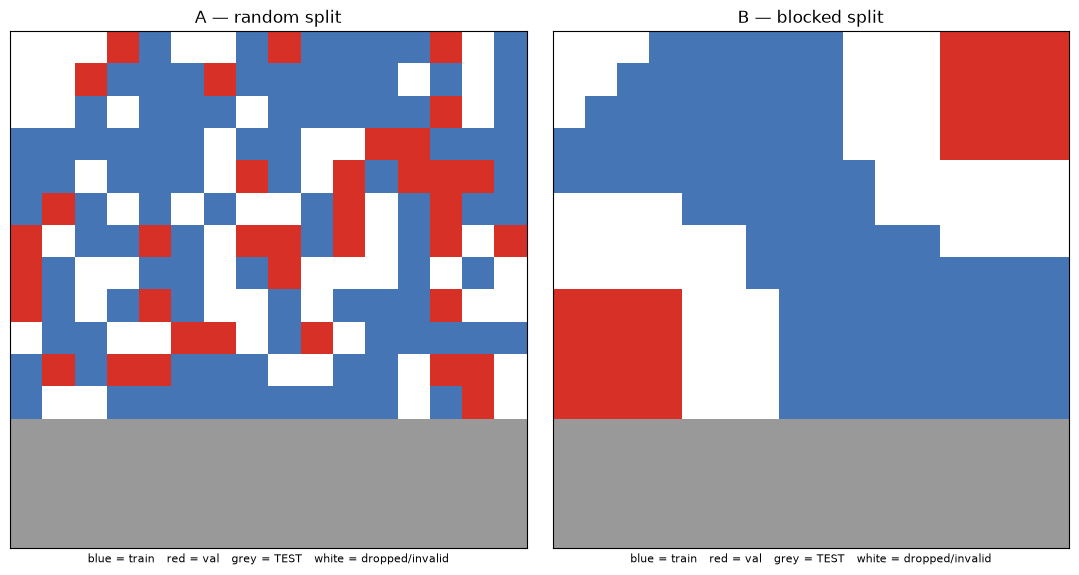

In [7]:
def split_map(tr, val, test, title):
    m = np.full((H // TILE, W // TILE), np.nan)
    for c, r in tr:   m[r // TILE, c // TILE] = 0
    for c, r in val:  m[r // TILE, c // TILE] = 1
    for c, r in test: m[r // TILE, c // TILE] = 2
    return m, title

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
pal = ListedColormap(["#4575b4", "#d73027", "#999999"])   # train, val, test
for a, (m, t) in zip(ax, [split_map(tr_rand, val_rand, test_tiles, "A — random split"),
                          split_map(tr_blk,  val_blk,  test_tiles, "B — blocked split")]):
    a.imshow(m, cmap=pal, vmin=0, vmax=2, interpolation="nearest")
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
    a.set_xlabel("blue = train   red = val   grey = TEST   white = dropped/invalid",
                 fontsize=8)
plt.tight_layout(); plt.show()

## 3b. Verifying the split before training anything

The maps are persuasive but not quantitative. The check that matters is: **how far is
the nearest training tile from each validation tile, relative to the measured range?**

If that distance is below the range for most validation tiles, the split leaks — and
this can be established before a single epoch is trained.

autocorrelation range: 360 px

split        median      min   val tiles inside the range
random          128      128                         100%
blocked         606      405                           0%


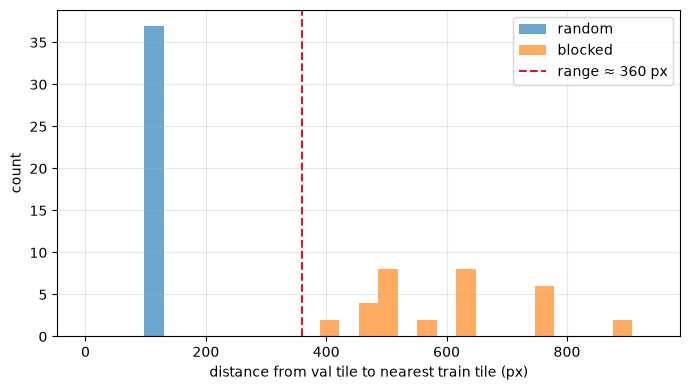

In [8]:
def nearest_train_distance(val_tiles, train_tiles):
    """Distance from each validation tile centre to the nearest training tile."""
    tc = np.array([[c + TILE/2, r + TILE/2] for c, r in train_tiles])
    return np.array([np.hypot(tc[:, 0] - (c + TILE/2), tc[:, 1] - (r + TILE/2)).min()
                     for c, r in val_tiles])

d_rand = nearest_train_distance(val_rand, tr_rand)
d_blk  = nearest_train_distance(val_blk,  tr_blk)

print(f"autocorrelation range: {RANGE_PX:.0f} px\n")
print(f"{'split':10s} {'median':>8s} {'min':>8s}   {'val tiles inside the range':>26s}")
for name, d in [("random", d_rand), ("blocked", d_blk)]:
    print(f"{name:10s} {np.median(d):8.0f} {d.min():8.0f}   "
          f"{(d < RANGE_PX).mean()*100:25.0f}%")

plt.figure(figsize=(7, 4))
bins = np.linspace(0, max(d_rand.max(), d_blk.max()) * 1.05, 30)
plt.hist(d_rand, bins=bins, alpha=.65, label="random")
plt.hist(d_blk,  bins=bins, alpha=.65, label="blocked")
plt.axvline(RANGE_PX, ls="--", c="crimson", label=f"range ≈ {RANGE_PX:.0f} px")
plt.xlabel("distance from val tile to nearest train tile (px)")
plt.ylabel("count"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

Expect the random split to put essentially every validation tile within the range — a
nearest neighbour one tile away — while the blocked split puts none of them there. **The
two histograms should not overlap**, with the range line between them.

If they do overlap, the buffer is too narrow and the training comparison below will
understate the effect.

The two maps are the clearest statement of the problem.

**In A, red validation tiles are scattered through blue training tiles** — most have a
training tile directly adjacent, sampling ground metres away.

**In B, validation occupies contiguous regions**, with a white buffer separating them
from training. No validation tile has a training neighbour within the autocorrelation
range.

Grey is the held-out southern quarter in both.

## 4. Dataset, model, training

Same components as Day 10: windowed GeoTIFF reads, per-band percentile normalization
with nodata excluded, `IGNORE` carried into the loss and filtered out of the metrics.

In [9]:
def band_stats(path, tiles, size=TILE, max_tiles=60, seed=0):
    """Per-band percentile statistics from TRAINING tiles only.

    Computing these over the whole scene would leak test-region statistics into
    the preprocessing -- a subtle version of the same error this notebook is about.
    """
    rng = np.random.default_rng(seed)
    pick = [tiles[i] for i in rng.permutation(len(tiles))[:max_tiles]]
    with rasterio.open(path) as src:
        nodv = src.nodata
        acc = [[] for _ in range(src.count)]
        for c, r in pick:
            a = src.read(window=Window(c, r, size, size)).astype(np.float64)
            for b in range(src.count):
                v = a[b][a[b] != nodv]
                if v.size: acc[b].append(v)
    out = {}
    for b, ch in enumerate(acc):
        v = np.concatenate(ch)
        lo, hi = np.percentile(v, [2, 98])
        out[b] = dict(lo=float(lo), hi=float(hi))
    return out


def norm_percentile(arr, stats):
    out = np.empty_like(arr, dtype=np.float32)
    for b in range(arr.shape[0]):
        lo, hi = stats[b]["lo"], stats[b]["hi"]
        out[b] = np.clip((arr[b] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


class TileDS(Dataset):
    def __init__(self, scene_path, label_path, tiles, stats, size=TILE):
        self.scene, self.label_path = scene_path, label_path
        self.tiles, self.stats, self.size = tiles, stats, size
        with rasterio.open(scene_path) as src:
            self.nod = src.nodata

    def __len__(self):
        return len(self.tiles)

    def __getitem__(self, i):
        c, r = self.tiles[i]
        w = Window(c, r, self.size, self.size)
        with rasterio.open(self.scene) as src:
            arr = src.read(window=w).astype(np.float32)
        with rasterio.open(self.label_path) as ls:
            y = ls.read(1, window=w).astype(np.int64)
        valid = (arr != self.nod).all(axis=0)
        x = torch.from_numpy(norm_percentile(arr, self.stats))
        x[:, ~valid] = 0.0
        y[~valid] = IGNORE
        return x, torch.from_numpy(y)

In [10]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=4, n_classes=N_CLS, base=16):
        super().__init__()
        b = base
        self.pool = nn.MaxPool2d(2)
        self.enc1 = DoubleConv(in_ch, b)
        self.enc2 = DoubleConv(b,   b*2)
        self.enc3 = DoubleConv(b*2, b*4)
        self.bottleneck = DoubleConv(b*4, b*8)
        self.up3  = nn.ConvTranspose2d(b*8, b*4, 2, stride=2)
        self.dec3 = DoubleConv(b*8, b*4)
        self.up2  = nn.ConvTranspose2d(b*4, b*2, 2, stride=2)
        self.dec2 = DoubleConv(b*4, b*2)
        self.up1  = nn.ConvTranspose2d(b*2, b, 2, stride=2)
        self.dec1 = DoubleConv(b*2, b)
        self.head = nn.Conv2d(b, n_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        bn = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(bn), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)


loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE)

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    cm = torch.zeros(N_CLS, N_CLS, dtype=torch.int64, device=device)
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        pred = model(xb).argmax(1)
        keep = yb != IGNORE                      # phantom class otherwise
        y, p = yb[keep], pred[keep]
        cm += torch.bincount(y * N_CLS + p, minlength=N_CLS**2).reshape(N_CLS, N_CLS)
    cm = cm.float(); tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    present = cm.sum(1) > 0
    return dict(acc=(tp.sum()/cm.sum()).item(),
                miou=iou[present].mean().item(), iou=iou.cpu().numpy())


def run_split(name, train_tiles, val_tiles, test_tiles, epochs=20, seed=42):
    """Train on one split and report validation AND held-out test scores."""
    stats = band_stats(scene, train_tiles)          # training tiles only
    tr_dl  = DataLoader(TileDS(scene, labels, train_tiles, stats), batch_size=16,
                        shuffle=True, num_workers=0)
    va_dl  = DataLoader(TileDS(scene, labels, val_tiles,   stats), batch_size=16,
                        shuffle=False, num_workers=0)
    te_dl  = DataLoader(TileDS(scene, labels, test_tiles,  stats), batch_size=16,
                        shuffle=False, num_workers=0)

    seed_all(seed)
    model = UNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best = {"miou": -1}

    for ep in range(epochs):
        t0 = time.time(); model.train()
        for xb, yb in tr_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        v = evaluate(model, va_dl)
        if v["miou"] > best["miou"]:
            best = v
            best_state = copy.deepcopy({k: t.cpu() for k, t in model.state_dict().items()})
            best_ep = ep + 1
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  [{name}] ep {ep+1:2d}  val mIoU {v['miou']:.4f}  ({time.time()-t0:.0f}s)")

    model.load_state_dict(best_state)               # select on validation, as usual
    te = evaluate(model, te_dl)
    print(f"  [{name}] best val mIoU {best['miou']:.4f} @ ep {best_ep}  ->  "
          f"TEST mIoU {te['miou']:.4f}  (optimism {best['miou']-te['miou']:+.4f})")
    return dict(name=name, val=best["miou"], test=te["miou"],
                val_iou=best["iou"], test_iou=te["iou"], best_ep=best_ep)

Note `band_stats(scene, train_tiles)` — **normalization statistics come from the
training tiles only.** Computing them over the whole scene would leak test-region
statistics into preprocessing: a quieter instance of the same error this notebook is
about, and one that survives even a correct blocked split.

Model selection still uses validation, exactly as in Day 6. The difference being tested
is only *which tiles the validation set contains*.

## 5. Run both splits

In [11]:
results = []
print("A — random split")
results.append(run_split("random",  tr_rand, val_rand, test_tiles))
print("\nB — blocked split")
results.append(run_split("blocked", tr_blk,  val_blk,  test_tiles))

print("\n" + "=" * 58)
print(f"{'split':10s} {'val mIoU':>10s} {'TEST mIoU':>11s} {'optimism':>11s}")
print("-" * 58)
for r in results:
    print(f"{r['name']:10s} {r['val']:10.4f} {r['test']:11.4f} "
          f"{r['val']-r['test']:+11.4f}")
print("=" * 58)

A — random split
  [random] ep  1  val mIoU 0.1337  (3s)
  [random] ep  5  val mIoU 0.5188  (1s)
  [random] ep 10  val mIoU 0.5253  (1s)
  [random] ep 15  val mIoU 0.5092  (1s)
  [random] ep 20  val mIoU 0.5055  (1s)
  [random] best val mIoU 0.5291 @ ep 12  ->  TEST mIoU 0.3638  (optimism +0.1653)

B — blocked split
  [blocked] ep  1  val mIoU 0.1390  (1s)
  [blocked] ep  5  val mIoU 0.4112  (1s)
  [blocked] ep 10  val mIoU 0.3847  (1s)
  [blocked] ep 15  val mIoU 0.3950  (1s)
  [blocked] ep 20  val mIoU 0.3852  (1s)
  [blocked] best val mIoU 0.4166 @ ep 12  ->  TEST mIoU 0.3725  (optimism +0.0441)

split        val mIoU   TEST mIoU    optimism
----------------------------------------------------------
random         0.5291      0.3638     +0.1653
blocked        0.4166      0.3725     +0.0441


## 6. Reading the result

Three things to check, in order.

**First: are the two TEST scores close?** Both models trained on the same number of
tiles from the same region, same architecture, same seed, and neither saw the southern
quarter. If TEST differs substantially, something other than the split strategy changed
and the comparison is void. Expect them within a point or two.

**Second: the optimism column.** This is the result. Random-split optimism should be
several times larger than blocked. That gap is the amount by which a random split
overstates what the model can do on ground it has not seen.

**Third: blocked optimism will not be zero,** and that is not a failure of the method.
The buffer removes adjacency, but the regional trend means the southern quarter is
genuinely a different distribution from anything in the northern pool. Blocked
validation answers "how well does this generalize to nearby unseen ground"; a held-out
region answers "how well does it generalize to a new region". **Those are different
questions, and only the second one is usually what deployment asks.**

A reference run of this notebook on CPU produced:

```
random   val 0.5284 -> TEST 0.3668   optimism +0.1616
blocked  val 0.4173 -> TEST 0.3613   optimism +0.0560
```

TEST within 0.6 points of each other, random optimism roughly 3x blocked. Your numbers
will differ — MPS and CPU take different arithmetic paths, and Day 6 measured ~1.2
points of run-to-run variance on a comparable setup — but the ordering and the rough
ratio should hold. **If they do not, say so rather than reinterpreting the plan.**

Note also that **the blocked model's validation score is lower than the random model's**
(0.42 vs 0.53) while their test scores match. The blocked number looks worse and is
closer to the truth. A practitioner comparing the two pipelines on validation score
alone would pick the leaky one.

## Limitations

*To be completed after the run.* Known in advance:

- **One scene, one seed per split.** Day 6 measured ~1.2 points of run-to-run variance
  on a comparable setup; a difference smaller than that would not be established. The
  observed gap (~10 points of optimism) is well clear of that, but it is not multi-seed.
- **The magnitude depends on `hidden_w`.** Section 1b shows the effect vanishes entirely
  at `hidden_w = 0`. How much of a real dataset's labels are unexplainable from its
  imagery is an empirical property of that dataset, so the size of the leakage here is a
  property of this construction. The mechanism, and the direction, are general.
- **Synthetic data.** The autocorrelation structure and trend are prescribed rather than
  observed, so the magnitude of the leakage is a property of this construction. The
  direction and mechanism are general; the number is not.
- **One block size and one buffer width.** `block_tiles=4` and a buffer rounded up from
  the measured range are reasonable defaults, not tuned. Tighter buffers would show the
  effect shrinking gradually rather than switching off.
- **The test region is a contiguous quarter**, so it confounds "new ground" with "ground
  further along the trend". A more careful design would hold out several scattered
  blocks. The confound makes test harder for both models equally, so it does not affect
  the comparison, but it does inflate both optimism figures.
- **No multi-seed check on which blocks become validation.** A different block
  assignment would change the blocked numbers somewhat.

## What this notebook is for

The deliverable is not an IoU. It is a measurement of **how much a random split lies**,
on data where the ground truth about generalization is available by construction.

For satellite work the practical rules that follow:

1. **Measure the autocorrelation range** before designing a split. The semivariogram is
   twenty lines of code and it turns a guess into a number.
2. **Split by geography, not by shuffling.** Blocks, scenes, dates, or orbits — whatever
   unit is genuinely independent for the data at hand.
3. **Buffer the boundary** by at least the range.
4. **Compute preprocessing statistics on training data only.** Scene-wide statistics leak
   through even a correct split.
5. **If the model will be deployed on new regions, hold out a region** — not a random
   subset. Blocked validation and regional hold-out answer different questions.

**Next:** pretrained encoders for segmentation, and adapting ImageNet weights to
multispectral input — the channel-count mismatch flagged in Day 5 and Day 10.